## Existing Public BERT-Based AI Text Detector

In this notebook, we evaluate an existing public BERT-based AI text detection model on the HC3 dataset. The purpose of this experiment is to test how well a pre-trained detector can distinguish between human-written text and AI-generated text without additional fine-tuning.

### Dataset Preparation

The dataset is loaded from the `all.jsonl` file. Each record contains two types of answers:

- `human_answers`, which are labelled as `0`
- `chatgpt_answers`, which are labelled as `1`

All non-empty answers are extracted and converted into a unified dataframe with two columns:

- `text`: the response content
- `label`: the ground-truth class

This produces a full dataset containing both human-written and AI-generated samples for evaluation.

### Model Selection

The model used in this notebook is:

`pritamdeb68/BERTAIDetector`

This is an existing public sequence classification model from Hugging Face. It is loaded directly with `AutoTokenizer` and `AutoModelForSequenceClassification`. Since the model is already pre-trained for AI text detection, no training or fine-tuning is performed in this notebook. Instead, the model is used directly for inference on the dataset.

### Inference Process

The full dataset is used for prediction. Text samples are processed in batches to improve efficiency. During tokenization:

- padding is applied
- truncation is enabled
- maximum sequence length is set to 256

If a CUDA-enabled GPU is available, the model runs on GPU for faster inference. Mixed precision (`float16`) is also used on CUDA devices to improve performance.

The model outputs logits, which are converted into probabilities using softmax. The predicted label is then obtained by selecting the class with the highest probability.

### Evaluation Metrics

After prediction, the model is evaluated using several standard classification metrics:

- Accuracy
- Precision
- Recall
- F1-score

A full classification report is also generated to show class-wise performance. These metrics help assess the model’s ability to classify human and AI-generated text correctly.

### Output and Visualisation

The notebook saves the prediction results into a CSV file named:

`existing_bert_model_full_predictions.csv`

This file includes:

- original text
- true label
- predicted label
- probability for class 0
- probability for class 1

In addition, two visualisations are produced:

1. **Confusion Matrix**  
   This shows how many samples were correctly or incorrectly classified as human or AI-generated.

2. **Evaluation Metrics Bar Chart**  
   This displays the overall Accuracy, Precision, Recall, and F1-score in a simple visual format.

### Summary

Overall, this notebook demonstrates how an existing public BERT-based AI detector can be applied directly to the HC3 dataset for binary classification. The workflow includes dataset construction, batched inference, quantitative evaluation, result saving, and visual analysis. This experiment serves as a baseline for comparing public pre-trained detectors with other models in the project.

d:\python\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Current working directory: d:\COMP6713\group hw\comp6713-ass2\model03_existing_bert_detector
Input file exists: True

Test set shape: (211185, 3)
Columns: ['text', 'label', 'dataset']

Label distribution:
label
0    155352
1     55833
Name: count, dtype: int64

Inference shape: (211185, 3)

Inference label distribution:
label
0    155352
1     55833
Name: count, dtype: int64

Using device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
CUDA version: 11.8


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
d:\python\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\25181\.cache\huggingface\hub\models--pritamdeb68--BERTAIDetector. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.micro


Loaded model: pritamdeb68/BERTAIDetector
id2label: {0: 'LABEL_0', 1: 'LABEL_1'}
label2id: {'LABEL_0': 0, 'LABEL_1': 1}
Model device: cuda:0
Input device: cuda:0


d:\python\Lib\site-packages\torch\nn\modules\module.py:1762: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `BertSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)



Unique predicted labels before adjustment: [0 1]

Existing Public BERT AI Detector Results (Shared Test Set)
Accuracy : 0.6664
Precision: 0.4260
Recall   : 0.7533
F1-score : 0.5442

Classification Report:
              precision    recall  f1-score   support

           0     0.8775    0.6352    0.7369    155352
           1     0.4260    0.7533    0.5442     55833

    accuracy                         0.6664    211185
   macro avg     0.6518    0.6943    0.6406    211185
weighted avg     0.7582    0.6664    0.6860    211185


Saved predictions to: existing_bert_model_test_predictions_compact.csv
Saved metrics to: existing_bert_model_test_metrics.json

Sample predictions:
   sample_id  true_label  pred_label   prob_ai
0          0           0           0  0.285400
1          1           0           1  0.996582
2          2           0           0  0.244141
3          3           0           0  0.144409
4          4           0           0  0.086365
5          5           0           0

d:\python\Lib\site-packages\pandas\io\formats\format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


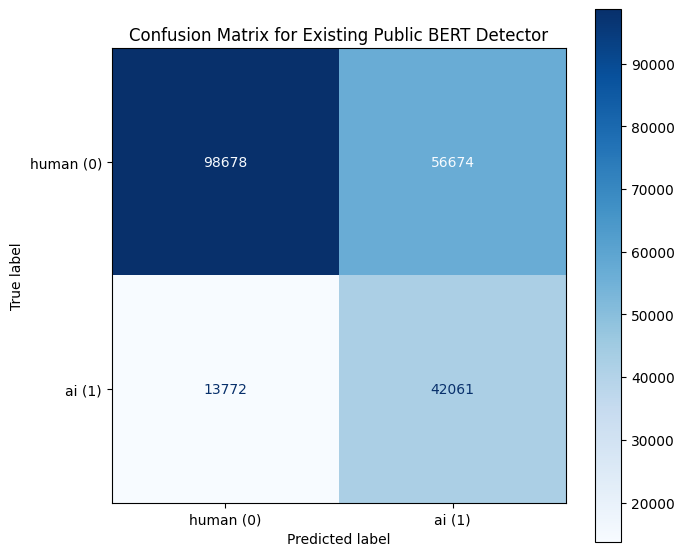

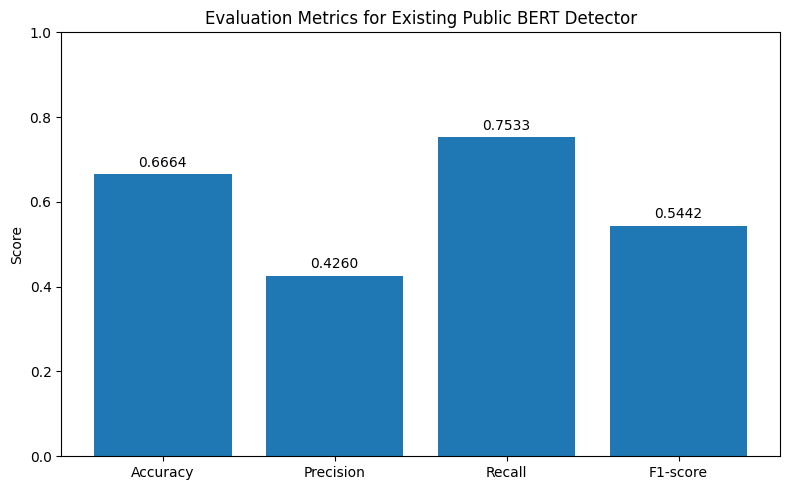

In [1]:
import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# =========================
# 1. Check current working directory
# =========================
print("Current working directory:", os.getcwd())

# =========================
# 2. Load shared test split
# 0 = human-written
# 1 = AI-generated
# =========================
input_path = "../data/splits/test.parquet"
print("Input file exists:", os.path.exists(input_path))

test_df = pd.read_parquet(input_path)

print("\nTest set shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
print("\nLabel distribution:")
print(test_df["label"].value_counts().sort_index())

# =========================
# 3. Use shared test split for inference
# =========================
full_df = test_df.copy()

print("\nInference shape:", full_df.shape)
print("\nInference label distribution:")
print(full_df["label"].value_counts().sort_index())

# Optional: use a smaller subset for debugging
# full_df = full_df.sample(n=5000, random_state=42)

# =========================
# 4. Device setting
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nUsing device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("CUDA is not available. Running on CPU.")

# =========================
# 5. Load existing public BERT AI detector
# =========================
MODEL_NAME = "pritamdeb68/BERTAIDetector"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

print("\nLoaded model:", MODEL_NAME)
print("id2label:", model.config.id2label)
print("label2id:", model.config.label2id)
print("Model device:", next(model.parameters()).device)

# =========================
# 6. Prepare test data
# =========================
full_texts = full_df["text"].astype(str).tolist()
y_true = full_df["label"].astype(int).tolist()

# =========================
# 7. Prediction function
# =========================
def predict_in_batches(texts, tokenizer, model, device, batch_size=32, max_length=256):
    all_preds = []
    all_probs = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        if i == 0:
            print("Input device:", inputs["input_ids"].device)

        with torch.inference_mode():
            if device.type == "cuda":
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    outputs = model(**inputs)
            else:
                outputs = model(**inputs)

            logits = outputs.logits
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

    return np.array(all_preds), np.array(all_probs)

# =========================
# 8. Run prediction on shared test split
# =========================
y_pred, y_prob = predict_in_batches(
    full_texts,
    tokenizer,
    model,
    device,
    batch_size=32,
    max_length=256
)

print("\nUnique predicted labels before adjustment:", np.unique(y_pred))

# =========================
# 9. IMPORTANT:
# Dataset labels:
# 0 = human
# 1 = ai
#
# Check model.config.id2label above.
# If reversed, uncomment below.
# =========================
# y_pred = 1 - y_pred
# y_prob = y_prob[:, ::-1]

# =========================
# 10. Evaluation
# =========================
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="binary", zero_division=0)
recall = recall_score(y_true, y_pred, average="binary", zero_division=0)
f1 = f1_score(y_true, y_pred, average="binary", zero_division=0)

print("\nExisting Public BERT AI Detector Results (Shared Test Set)")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, digits=4))

# =========================
# 11. Save compact predictions
# =========================
results_df = pd.DataFrame({
    "sample_id": range(len(y_true)),
    "y_true": y_true,
    "y_pred": y_pred,
    "prob_ai": y_prob[:, 1]
})

output_path = "existing_bert_model_test_predictions_compact.csv"
results_df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("\nSaved predictions to:", output_path)

# =========================
# 12. Save metrics
# =========================
metrics = {
    "Model": "Model 03 Existing Public BERT Detector",
    "Accuracy": float(accuracy),
    "Precision": float(precision),
    "Recall": float(recall),
    "F1-score": float(f1)
}

metrics_output_path = "existing_bert_model_test_metrics.json"
with open(metrics_output_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Saved metrics to:", metrics_output_path)

# =========================
# 13. Quick manual inspection
# =========================
sample_check = pd.DataFrame({
    "sample_id": range(min(10, len(full_df))),
    "true_label": y_true[:10],
    "pred_label": y_pred[:10],
    "prob_ai": y_prob[:10, 1]
})

print("\nSample predictions:")
print(sample_check)

# =========================
# 14. Confusion matrix
# =========================
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:")
print(cm)

# =========================
# 15. Plot confusion matrix
# =========================
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["human (0)", "ai (1)"]
)
disp.plot(cmap="Blues", values_format="d", ax=ax)
ax.set_title("Confusion Matrix for Existing Public BERT Detector")
plt.tight_layout()
plt.show()

# =========================
# 16. Plot evaluation metrics
# =========================
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]
metric_values = [accuracy, precision, recall, f1]

plt.figure(figsize=(8, 5))
bars = plt.bar(metric_names, metric_values)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Evaluation Metrics for Existing Public BERT Detector")

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [2]:
print("Test set shape:", test_df.shape)
print("len(y_true):", len(y_true))
print("len(y_pred):", len(y_pred))
print("Confusion matrix sum:", cm.sum())
print("id2label:", model.config.id2label)
print("label2id:", model.config.label2id)

Test set shape: (211185, 3)
len(y_true): 211185
len(y_pred): 211185
Confusion matrix sum: 211185
id2label: {0: 'LABEL_0', 1: 'LABEL_1'}
label2id: {'LABEL_0': 0, 'LABEL_1': 1}
